In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay


In [2]:

df = pd.read_csv("iris (2).csv")
print("Rows and columns:", df.shape)
print("\nFirst five rows:\n", df.head())
print("\nMissing values:\n", df.isna().sum())
print("\nSpecies counts:\n", df["species"].value_counts())


Rows and columns: (150, 5)

First five rows:
    sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Missing values:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species counts:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:

features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = df[features]
y = df["species"]


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

k_values = [1, 3, 5, 7, 9, 11]
cv_accuracies = []
test_accuracies = []



Training samples: 120
Testing samples: 30


In [5]:

for k in k_values:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    cv_accuracies.append(cv_scores.mean())
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    test_accuracies.append(accuracy_score(y_test, predictions))
    print(f"K={k:2d} | CV Accuracy={cv_accuracies[-1]:.4f} | Test Accuracy={test_accuracies[-1]:.4f}")

best_index = cv_accuracies.index(max(cv_accuracies))
best_k = k_values[best_index]
print("\nSelected K:", best_k)


K= 1 | CV Accuracy=0.9417 | Test Accuracy=0.9667
K= 3 | CV Accuracy=0.9583 | Test Accuracy=0.9333
K= 5 | CV Accuracy=0.9667 | Test Accuracy=0.9333
K= 7 | CV Accuracy=0.9583 | Test Accuracy=0.9667
K= 9 | CV Accuracy=0.9583 | Test Accuracy=0.9667
K=11 | CV Accuracy=0.9583 | Test Accuracy=0.9667

Selected K: 5


In [6]:

best_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
best_model.fit(X_train, y_train)
final_predictions = best_model.predict(X_test)


In [7]:

print("\nFinal test accuracy:", accuracy_score(y_test, final_predictions))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, final_predictions))
print("\nClassification Report:\n", classification_report(y_test, final_predictions))



Final test accuracy: 0.9333333333333333

Confusion Matrix:
 [[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



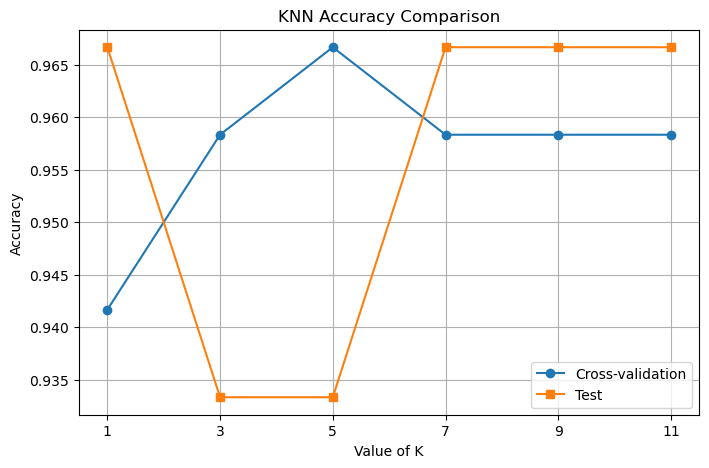

In [8]:

plt.figure(figsize=(8, 5))
plt.plot(k_values, cv_accuracies, marker="o", label="Cross-validation")
plt.plot(k_values, test_accuracies, marker="s", label="Test")
plt.xlabel("Value of K")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy Comparison")
plt.xticks(k_values)
plt.legend()
plt.grid()
plt.show()


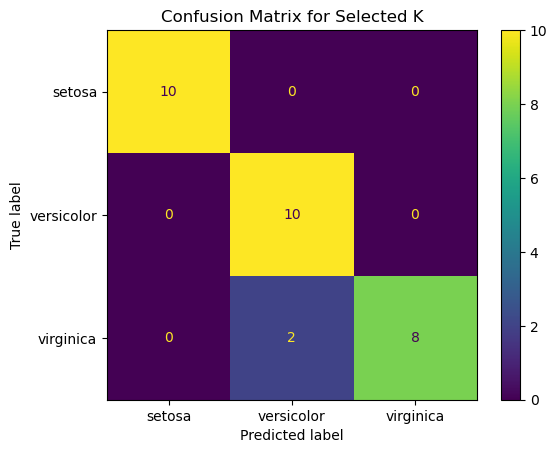

In [9]:

ConfusionMatrixDisplay.from_predictions(y_test, final_predictions)
plt.title("Confusion Matrix for Selected K")
plt.show()


In [10]:

new_flower = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=features)
new_prediction = best_model.predict(new_flower)
print("\nPredicted species for new flower:", new_prediction[0])



Predicted species for new flower: setosa
